# Transformer Decoder-Only: costruzione e addestramento completo (Keras)

Questo notebook contiene **solo** ciò che serve per costruire e addestrare per intero un Transformer **decoder-only** (stile GPT) in Keras/TensorFlow: niente GPT-2 pre-addestrato, niente Hugging Face/PyTorch, e niente derivazioni matematiche a mano — solo l'architettura, il training vero, e la generazione col modello addestrato.

## Teoria iniziale: cosa fa ogni blocco e come si lega al successivo

Prima di entrare nel codice, ecco una mappa di TUTTO il percorso: cosa costruisce/fa ciascun blocco, e perché serve al blocco successivo. Ogni blocco usa il risultato concreto (una variabile, una classe, un modello) prodotto da quello precedente — non sono esempi indipendenti.

**Blocco 1 — Setup**
- *Cosa fa:* importa le librerie (numpy, pandas, matplotlib, seaborn, tensorflow/keras) e fissa i seed casuali.
- *Perché serve dopo:* tutti i blocchi successivi useranno `tf`/`keras`/`layers` per costruire il modello e `plt` per i grafici. Senza questo blocco, nessuna riga di codice successiva funzionerebbe.

**Blocco 2 — Architettura decoder-only in Keras**
- *Cosa fa:* definisce le classi `PositionalEncoding`, `DecoderBlock` e `MiniGPT` (con `use_causal_mask=True`, la riga che rende il modello decoder-only), poi crea un'istanza `mini_gpt` e la testa con pesi **casuali** (nessun training) solo per verificare che shape e numero di parametri siano corretti.
- *Perché serve dopo:* il Blocco 3 userà `mini_gpt` per una foto "prima del training", e il Blocco 4 riuserà la STESSA classe `MiniGPT` (non una nuova) per creare il modello che verrà davvero addestrato. Se questo blocco non gira, nessuno dei successivi può girare: è la fondazione di tutto il notebook.

**Blocco 3 — Visualizzazione PRIMA del training**
- *Cosa fa:* usa `mini_gpt` (pesi ancora casuali, creato nel Blocco 2) per guardare un embedding e la matrice di self-attention causale.
- *Perché serve dopo:* è la "fotografia di partenza". Il Blocco 5 ripeterà l'identica visualizzazione ma sul modello addestrato: senza questo blocco non avremmo nulla con cui confrontare il "dopo".

**Blocco 4 — Addestramento completo** (diviso in 6 passaggi che si susseguono in ordine)
- *Cosa fa, passo per passo:*
  1. **Corpus e tokenizzazione**: crea un corpus giocattolo e lo trasforma in id numerici (`word_to_id`/`id_to_word`).
  2. **Input e target**: dagli id costruisce `X_train`/`y_train` per il compito di next-token prediction.
  3. **Creazione del modello**: usa la classe `MiniGPT` del Blocco 2 per creare `mini_gpt_train` (dimensioni più piccole, adatte al corpus giocattolo).
  4. **Compile**: definisce optimizer, loss e metrica (nessun training ancora).
  5. **Training (fit)**: qui avviene davvero l'addestramento, 100 epoche.
  6. **Grafici di loss e accuracy**: leggono `history` (prodotto dal `fit()`) per verificare che il modello abbia imparato.
- *Perché serve dopo:* produce `mini_gpt_train` con pesi **aggiornati dal training**: è l'oggetto che useranno sia il Blocco 5 (per il confronto "dopo") sia il Blocco 6 (per generare testo). Ogni passaggio di questo blocco dipende dal precedente (non si può fare il fit senza aver prima compilato, non si può compilare senza aver prima creato il modello, ecc.).

**Blocco 5 — Visualizzazione DOPO il training**
- *Cosa fa:* ripete esattamente la visualizzazione del Blocco 3, ma su `mini_gpt_train` invece che su `mini_gpt`.
- *Perché serve dopo:* rende visibile, col confronto diretto Blocco 3 vs Blocco 5, cosa ha cambiato concretamente il training nei pesi di attenzione. Prepara anche concettualmente il Blocco 6: se l'attenzione è cambiata, ci aspettiamo che anche le predizioni del modello siano cambiate.

**Blocco 6 — Generazione autoregressiva**
- *Cosa fa:* usa `mini_gpt_train` (lo stesso modello addestrato nel Blocco 4) per generare testo un token alla volta, a partire da una frase seed.
- *Perché è l'ultimo blocco:* è il "punto di arrivo" del notebook: mostra concretamente cosa significa avere un modello decoder-only addestrato, chiudendo il cerchio apertosi nel Blocco 2 (architettura non addestrata) e attraversato dal Blocco 4 (addestramento).

## Percorso del notebook (riepilogo rapido)
1. Setup
2. Architettura decoder-only in Keras (pesi allenabili, ma non ancora addestrati)
3. Visualizzazione PRE-training
4. **Addestramento completo**: corpus, tokenizzazione, compile, fit
5. Visualizzazione POST-training (confronto col punto 3)
6. Generazione autoregressiva col modello addestrato

Ogni sezione di codice è introdotta da una spiegazione in 3(+1) parti: **Legame col blocco precedente**, **Cosa viene fatto realmente**, **Strumenti usati**, **Obiettivo**.


## Blocco 1 — Setup

🔗 **Legame col blocco precedente:** punto di partenza del notebook.

🔍 **Cosa viene fatto realmente:** importiamo numpy/pandas/matplotlib/seaborn (per i dati e i grafici) e tensorflow/keras (per architettura e training). Fissiamo dei seed per rendere i risultati riproducibili.

🛠️ **Strumenti usati:** `numpy`, `pandas`, `matplotlib.pyplot`, `seaborn` (analisi/grafici); `tensorflow` / `tensorflow.keras` (rete neurale); `tf.random.set_seed`, `np.random.seed`, `random.seed` (riproducibilità).

🎯 **Obiettivo:** ambiente pronto, senza dipendenze superflue (nessuna libreria per caricare modelli pre-addestrati).


In [1]:
# ============================================================
# SETUP — solo le librerie che servono davvero
# ============================================================
# Questo notebook NON usa Hugging Face / PyTorch / GPT-2:
# costruiamo e ADDESTRIAMO un Transformer decoder-only nostro,
# interamente in TensorFlow/Keras. Per questo il setup è più
# leggero rispetto al notebook "05_Transformer_e_LLM" (quello
# che invece carica GPT-2 pre-addestrato).
# ============================================================

# Se le librerie non sono già installate nell'ambiente
# (venv-transformer), scommenta la riga seguente:
!pip install tensorflow keras numpy matplotlib seaborn pandas

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import warnings
warnings.filterwarnings('ignore')

# TensorFlow e Keras: qui costruiamo E alleniamo il modello,
# non solo lo dimostriamo.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Configurazione grafica e seed per rendere l'esperimento
# riproducibile (stessi numeri casuali ad ogni esecuzione).
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

print("Setup completato.")
print(f"TensorFlow version: {tf.__version__}")
print(f"Keras version: {keras.__version__}")


Setup completato.
TensorFlow version: 2.21.0
Keras version: 3.15.1


## Blocco 2 — Architettura decoder-only in Keras

🔗 **Legame col blocco precedente:** con l'ambiente pronto, definiamo subito l'architettura che useremo per tutto il resto del notebook.

🔍 **Cosa viene fatto realmente:** definiamo `PositionalEncoding`, `DecoderBlock` e `MiniGPT` come vere classi Keras (`tf.keras.layers.Layer` / `tf.keras.Model`), con pesi **reali e allenabili**. In questa cella li testiamo solo con valori casuali: **nessun training è ancora avvenuto**.

🛠️ **Strumenti usati:** `tf.keras.layers.Layer` e `tf.keras.Model` (classi base per costruire livelli/modelli custom); `layers.Embedding`; `layers.MultiHeadAttention` con `use_causal_mask=True`; `layers.LayerNormalization`; `layers.Dropout`; `tf.keras.Sequential` (per la Feed-Forward Network); `model.summary()` e `model.count_params()` per ispezionare l'architettura.

🎯 **Obiettivo:** avere l'architettura pronta per l'addestramento. Punto chiave: `use_causal_mask=True` dentro `DecoderBlock.call()`. È questa riga — non il nome della classe — che rende il modello **decoder-only**: ogni token può guardare solo i token precedenti, mai quelli futuri.


In [ ]:
# ============================================================
# ARCHITETTURA DECODER-ONLY IN KERAS
# ============================================================
# Passiamo dal numpy scritto a mano a vere classi Keras.
# Le classi qui sotto definiscono livelli con PESI VERI, che
# potranno essere aggiornati da un training (compile + fit),
# a differenza delle sezioni precedenti dove le matrici erano
# fisse o casuali e non apprendevano nulla.
#
# SCELTA ARCHITETTURALE: questo è un modello DECODER-ONLY, non
# un encoder. Il punto cruciale è `use_causal_mask=True` nella
# chiamata alla Multi-Head Attention: significa che il token in
# posizione i può guardare solo i token in posizione <= i (il
# "passato"), mai il "futuro". Questo è esattamente il
# comportamento di GPT: predire il prossimo token vedendo solo
# quello che lo precede. Un encoder (come in BERT) NON userebbe
# questa maschera: guarderebbe la frase per intero, in entrambe
# le direzioni.
# ============================================================

print("ARCHITETTURA DECODER-ONLY (stile GPT)\n")


class PositionalEncoding(layers.Layer):
    """Aggiunge informazione sulla posizione di ciascun token.

    Senza questo livello, il modello vedrebbe l'input come un
    insieme di token senza ordine: "gatto il dorme" sarebbe
    indistinguibile da "il gatto dorme".
    """

    def __init__(self, max_len=5000, d_model=512):
        super().__init__()
        self.d_model = d_model  # lunghezza del vettore, è un valore che si imposta dopo il primo embedding
        # decidi quanto la matriche deve essere grande, 512 è un numero standard

        # Formula standard "Attention Is All You Need":
        # onde sinusoidali a frequenze diverse per ogni dimensione.
        pe = np.zeros((max_len, d_model))
        # pe = position encoding
        position = np.arange(0, max_len)[:, np.newaxis]
        div_term = np.exp(np.arange(0, d_model, 2) * -(np.log(10000.0) / d_model))
        pe[:, 0::2] = np.sin(position * div_term)
        pe[:, 1::2] = np.cos(position * div_term)

        # Il positional encoding è FISSO (non è un peso allenabile):
        # è una funzione matematica della posizione, non qualcosa
        # che il training deve imparare.
        self.pe = tf.constant(pe, dtype=tf.float32)

    def call(self, x):
        seq_len = tf.shape(x)[1]
        return x + self.pe[:seq_len, :]


class DecoderBlock(layers.Layer):
    """Un blocco decoder-only causale (il "mattoncino" che ripetiamo N volte).

    Struttura: Multi-Head Attention (causale) + residuo + LayerNorm,
    poi Feed-Forward + residuo + LayerNorm. Questa è la stessa
    struttura del Transformer Block "Attention Is All You Need",
    con la differenza che qui la self-attention è mascherata (causale).
    """

    def __init__(self, d_model, num_heads, dff, dropout_rate=0.1):
        super().__init__()
        self.d_model = d_model
        self.num_heads = num_heads

        # Multi-Head Attention già pronta di Keras: i pesi W_q, W_k,
        # W_v, W_o qui sono VERI parametri allenabili del modello.
        self.mha = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=d_model // num_heads,
            dropout=dropout_rate,
        )

        # Feed Forward Network: due Dense con una non-linearità in mezzo.
        self.ffn = tf.keras.Sequential([
            layers.Dense(dff, activation='relu'),
            layers.Dense(d_model),
        ])

        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)

        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)

    def call(self, x, training=False):
        # use_causal_mask=True: QUESTO è ciò che rende il blocco
        # decoder-only. Ogni posizione i puo' attingere solo dalle
        # posizioni <= i (self-attention mascherata / causale).
        attn_output = self.mha(
            x, x, x,
            training=training,
            use_causal_mask=True,
        )
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(x + attn_output)  # connessione residua + norm

        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        out2 = self.layernorm2(out1 + ffn_output)  # connessione residua + norm

        return out2


class MiniGPT(tf.keras.Model):
    """Transformer decoder-only in miniatura, in stile GPT.

    Embedding -> Positional Encoding -> N DecoderBlock -> proiezione
    finale sul vocabolario. Predice, per ogni posizione, la
    distribuzione di probabilità sul token successivo.
    """

    def __init__(self, vocab_size, d_model, num_heads, num_layers, dff,
                 max_len=1000, dropout_rate=0.1):
        super().__init__()
        self.d_model = d_model
        self.vocab_size = vocab_size

        self.embedding = layers.Embedding(vocab_size, d_model)
        self.pos_encoding = PositionalEncoding(max_len, d_model)

        # N blocchi decoder impilati: più blocchi = modello più profondo.
        self.decoder_blocks = [
            DecoderBlock(d_model, num_heads, dff, dropout_rate)
            for _ in range(num_layers)
        ]

        # Proiezione finale: da d_model a vocab_size, per ottenere
        # un punteggio (logit) per ogni parola del vocabolario.
        self.final_layer = layers.Dense(vocab_size)

        self.dropout = layers.Dropout(dropout_rate)

    def call(self, x, training=False):
        # Embedding + scaling (come nel paper originale, per bilanciare
        # la scala tra embedding e positional encoding)
        x = self.embedding(x)
        x *= tf.math.sqrt(tf.cast(self.d_model, tf.float32))

        x = self.pos_encoding(x)
        x = self.dropout(x, training=training)

        for decoder_block in self.decoder_blocks:
            x = decoder_block(x, training=training)

        # Output: un vettore di logit per ogni posizione della sequenza
        return self.final_layer(x)


# ------------------------------------------------------------
# Test dell'architettura con PESI ANCORA CASUALI (nessun training
# è stato fatto in questa cella: verifichiamo solo che le shape
# e il numero di parametri siano quelli attesi).
# ------------------------------------------------------------
print("TEST ARCHITETTURA (pesi non ancora addestrati):\n")

vocab_size = 1000
d_model = 128
num_heads = 8
num_layers = 4
dff = 512
max_len = 100
dropout_rate = 0.1

print("CONFIGURAZIONE:")
print(f"   Vocab size: {vocab_size:,}")
print(f"   Model dimension: {d_model}")
print(f"   Attention heads: {num_heads}")
print(f"   Decoder blocks: {num_layers}")
print(f"   FFN dimension: {dff}")

mini_gpt = MiniGPT(
    vocab_size=vocab_size,
    d_model=d_model,
    num_heads=num_heads,
    num_layers=num_layers,
    dff=dff,
    max_len=max_len,
    dropout_rate=dropout_rate,
)

batch_size = 2
seq_len = 10
test_input = tf.random.uniform((batch_size, seq_len), maxval=vocab_size, dtype=tf.int32)

print(f"\nTEST INPUT shape: {test_input.shape}")

output = mini_gpt(test_input, training=False)

print(f"OUTPUT shape: {output.shape}  (batch_size, seq_len, vocab_size)")

total_params = mini_gpt.count_params()
print(f"\nPARAMETRI TOTALI (ancora casuali, non addestrati): {total_params:,}")

mini_gpt.build(input_shape=(None, seq_len))
mini_gpt.summary()

print("\nPERCHE' E' UN DECODER-ONLY E NON UN ENCODER:")
print("   - use_causal_mask=True dentro DecoderBlock.call()")
print("   - ogni token vede solo i token che lo precedono")
print("   - è lo stesso principio autoregressivo usato da GPT")


ARCHITETTURA DECODER-ONLY (stile GPT)

TEST ARCHITETTURA (pesi non ancora addestrati):

CONFIGURAZIONE:
   Vocab size: 1,000
   Model dimension: 128
   Attention heads: 8
   Decoder blocks: 4
   FFN dimension: 512

TEST INPUT shape: (2, 10)
OUTPUT shape: (2, 10, 1000)  (batch_size, seq_len, vocab_size)

PARAMETRI TOTALI (ancora casuali, non addestrati): 1,050,088


Model: "mini_gpt_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (2, 10, 128)           │       128,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_encoding_2           │ ?                      │             0 │
│ (PositionalEncoding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block_6 (DecoderBlock)  │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block_7 (DecoderBlock)  │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block_8 (DecoderBlock)  │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_block_9 (DecoderBlock)  │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (2, 10, 1000)          │       129,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ ?                      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,050,088 (4.01 MB)

 Trainable params: 1,050,088 (4.01 MB)

 Non-trainable params: 0 (0.00 B)


PERCHE' E' UN DECODER-ONLY E NON UN ENCODER:
   - use_causal_mask=True dentro DecoderBlock.call()
   - ogni token vede solo i token che lo precedono
   - è lo stesso principio autoregressivo usato da GPT


## Blocco 3 — Visualizzazione PRIMA del training

🔗 **Legame col blocco precedente:** usiamo lo stesso modello `mini_gpt` appena creato, con i suoi pesi casuali, per fotografare "il punto di partenza".

🔍 **Cosa viene fatto realmente:** guardiamo l'embedding di alcuni token e la matrice di self-attention causale del primo blocco decoder, **senza aver fatto alcun training**.

🛠️ **Strumenti usati:** `mini_gpt.embedding(...)` (per estrarre i vettori embedding); `mini_gpt.pos_encoding(...)`; `block.mha(..., return_attention_scores=True, use_causal_mask=True)` per leggere i pesi interni dell'attenzione; `matplotlib.pyplot.imshow` per le heatmap.

🎯 **Obiettivo:** avere un riferimento "prima" da confrontare con lo stesso grafico "dopo" l'addestramento (Blocco 5).


EMBEDDING PRIMA DEL TRAINING

Token id: [10 25 37 42]
Shape embedding: (1, 4, 128)
Primi 10 valori dell'embedding del primo token:
[-0.025 -0.037  0.047  0.004  0.014  0.018 -0.019 -0.03   0.023 -0.039]


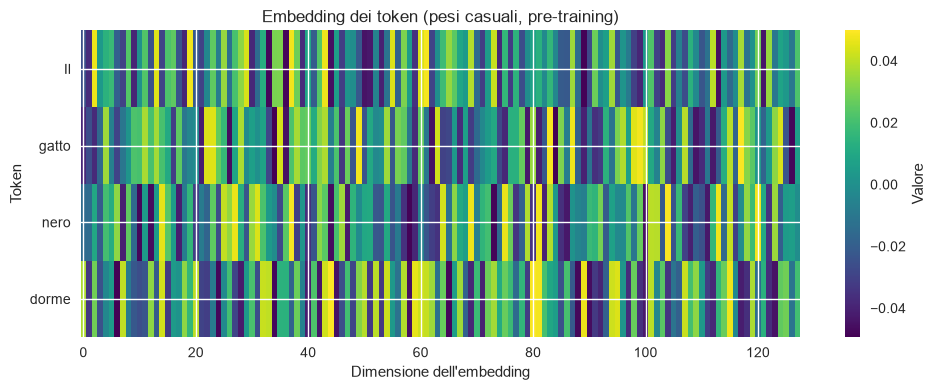


SELF-ATTENTION CAUSALE PRIMA DEL TRAINING

Frase: una storia bella divertente ciao
Shape dei pesi di attenzione: (1, 8, 5, 5)

Matrice di Self-Attention causale - Head 1 (pre-training):

[[1.    0.    0.    0.    0.   ]
 [0.497 0.503 0.    0.    0.   ]
 [0.33  0.334 0.337 0.    0.   ]
 [0.244 0.247 0.251 0.257 0.   ]
 [0.19  0.193 0.198 0.201 0.217]]


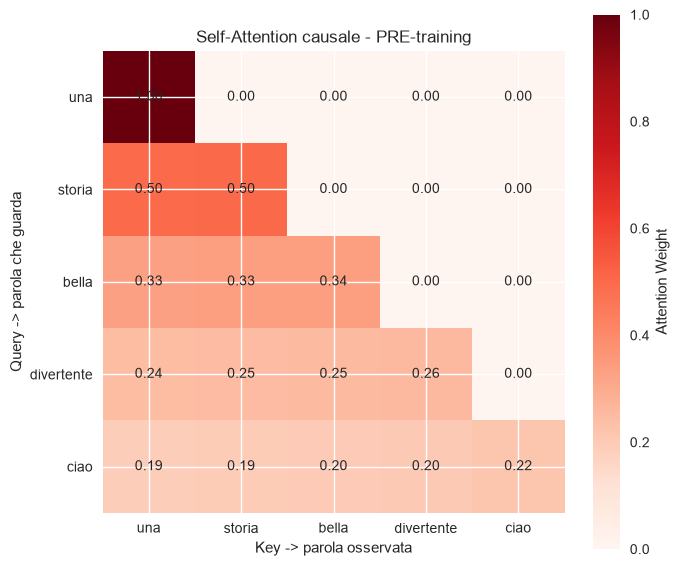


Da notare: la parte TRIANGOLARE SUPERIORE della matrice è a
zero (nessuna attenzione), perché la maschera causale impedisce
a ogni parola di guardare le parole che vengono dopo di lei.
Questo è già vero PRIMA del training: è una proprietà della
maschera, non qualcosa che il modello deve imparare.


In [15]:
# ============================================================
# VISUALIZZAZIONE PRIMA DEL TRAINING
# ============================================================
# Usiamo il modello mini_gpt appena creato (pesi ancora casuali,
# NESSUN training eseguito finora) per vedere due cose:
#   1) come appare un embedding prima di essere addestrato
#   2) come appare la matrice di self-attention causale, quando
#      ancora non ha imparato nulla dal corpus
#
# Questo ci servirà come "fotografia PRIMA" da confrontare con
# la stessa visualizzazione DOPO il training, più avanti nel
# notebook.
# ============================================================

print("EMBEDDING PRIMA DEL TRAINING\n")

input_ids = tf.constant([[10, 25, 37, 42]])
embeddings = mini_gpt.embedding(input_ids)

print("Token id:", input_ids.numpy()[0])
print("Shape embedding:", embeddings.shape)
print("Primi 10 valori dell'embedding del primo token:")
print(np.round(embeddings[0, 0, :10].numpy(), 3))

plt.figure(figsize=(10, 4))
plt.imshow(embeddings[0].numpy(), aspect="auto", cmap="viridis")
plt.colorbar(label="Valore")
plt.xlabel("Dimensione dell'embedding")
plt.ylabel("Token")
plt.yticks(range(4), ["Il", "gatto", "nero", "dorme"])
plt.title("Embedding dei token (pesi casuali, pre-training)")
plt.tight_layout()
plt.show()


print("\nSELF-ATTENTION CAUSALE PRIMA DEL TRAINING\n")

parole = ["una", "storia", "bella", "divertente", "ciao"]
input_ids2 = tf.constant([[10, 25, 37, 42, 60]])

print("Frase:", " ".join(parole))

# Passo manuale attraverso embedding + positional encoding, per poter
# poi leggere i pesi di attenzione del primo blocco decoder.
x = mini_gpt.embedding(input_ids2)
x = mini_gpt.pos_encoding(x)

block = mini_gpt.decoder_blocks[0]

# return_attention_scores=True: chiediamo a Keras di restituirci
# anche i pesi interni, non solo l'output finale.
# use_causal_mask=True: stessa maschera usata durante il training.
attention_output, attention_scores = block.mha(
    x, x, x,
    return_attention_scores=True,
    use_causal_mask=True,
    training=False,
)

print("Shape dei pesi di attenzione:", attention_scores.shape)

# Prendiamo la prima head (indice [batch=0, head=0])
attention_matrix = attention_scores[0, 0].numpy()

print("\nMatrice di Self-Attention causale - Head 1 (pre-training):\n")
print(np.round(attention_matrix, 3))

plt.figure(figsize=(7, 6))
plt.imshow(attention_matrix, cmap="Reds")
plt.colorbar(label="Attention Weight")
plt.xticks(range(len(parole)), parole)
plt.yticks(range(len(parole)), parole)
plt.xlabel("Key -> parola osservata")
plt.ylabel("Query -> parola che guarda")
plt.title("Self-Attention causale - PRE-training")

for i in range(len(parole)):
    for j in range(len(parole)):
        plt.text(j, i, f"{attention_matrix[i, j]:.2f}", ha="center", va="center")

plt.tight_layout()
plt.show()

print("\nDa notare: la parte TRIANGOLARE SUPERIORE della matrice è a")
print("zero (nessuna attenzione), perché la maschera causale impedisce")
print("a ogni parola di guardare le parole che vengono dopo di lei.")
print("Questo è già vero PRIMA del training: è una proprietà della")
print("maschera, non qualcosa che il modello deve imparare.")


## Blocco 4 — Addestramento completo

🔗 **Legame col blocco precedente:** abbiamo l'architettura e sappiamo come appare "prima". Ora le diamo davvero un corpus da imparare.

🔍 **Cosa viene fatto realmente:** creiamo un corpus giocattolo di poche frasi ripetute con variazioni e lo tokenizziamo a livello di parola. Il corpus è volutamente minuscolo: l'obiettivo è vedere la meccanica del training in pochi secondi.

🛠️ **Strumenti usati:** `str.lower().split()` (tokenizzazione a parole, senza subword/BPE); `sorted(set(...))` per costruire il vocabolario; dict comprehension per le mappe `word_to_id` / `id_to_word`.

🎯 **Obiettivo:** avere dati numerici (id di token) su cui calcolare una loss.


In [16]:
# ============================================================
# ADDESTRAMENTO: preparazione del corpus
# ============================================================
# Da qui in avanti eseguiamo un vero addestramento. Usiamo un
# corpus giocattolo piccolissimo (poche frasi ripetute con
# variazioni) apposta: con un corpus enorme l'addestramento
# richiederebbe ore/giorni e non sarebbe adatto a una lezione.
# L'obiettivo non è ottenere un modello linguisticamente ricco,
# ma vedere con i nostri occhi la meccanica di un training:
# dati -> loss -> aggiornamento pesi -> risultato.
# ============================================================

print("ADDESTRAMENTO DEL DECODER-ONLY\n")

testo_train = """
il gatto dorme
il gatto mangia
il gatto corre
il cane dorme
il cane mangia
il cane corre
il gatto è nero
il cane è felice
il gatto è felice
il cane è nero
"""

# Tokenizzazione semplicissima: ogni parola è un token
# (nessun subword/BPE come in GPT-2: qui va bene così per un
# vocabolario di poche parole).
tokens_train = testo_train.lower().split()

# Vocabolario: insieme delle parole distinte, con un id numerico
# assegnato a ciascuna (necessario perché la rete lavora con numeri,
# non con stringhe).
vocab_train = sorted(set(tokens_train))
word_to_id = {word: i for i, word in enumerate(vocab_train)}
id_to_word = {i: word for word, i in word_to_id.items()}
vocab_size_train = len(vocab_train)

print(f"Vocabolario: {vocab_train}")
print(f"Numero di token distinti: {vocab_size_train}")


ADDESTRAMENTO DEL DECODER-ONLY

Vocabolario: ['cane', 'corre', 'dorme', 'felice', 'gatto', 'il', 'mangia', 'nero', 'è']
Numero di token distinti: 9


### Input e target: next-token prediction

🔗 **Legame col blocco precedente:** abbiamo gli id dei token; ora li organizziamo in coppie (input, target) per il training.

🔍 **Cosa viene fatto realmente:** per ogni finestra di `seq_len_train` token, il target è la stessa finestra spostata di una posizione in avanti (**next-token prediction**, lo stesso compito usato per addestrare GPT).

🛠️ **Strumenti usati:** slicing di liste Python per la finestra scorrevole; `np.array(...)` per ottenere i tensori `X_train`/`y_train` nel formato che Keras si aspetta.

🎯 **Obiettivo:** ottenere `X_train`/`y_train` pronti per `.fit()`.


In [17]:
# ============================================================
# INPUT E TARGET: next-token prediction
# ============================================================
# Il compito di training è "next-token prediction": data una
# finestra di seq_len_train token, il modello deve prevedere,
# per OGNI posizione, il token immediatamente successivo.
#
# Questo è esattamente il compito che rende un modello
# "decoder-only autoregressivo": è lo stesso principio di
# addestramento usato (su scala enormemente più grande) per GPT.
# ============================================================

seq_len_train = 5
token_ids_train = [word_to_id[token] for token in tokens_train]

X_train = []
y_train = []

# Finestra scorrevole sul testo tokenizzato: per ogni posizione i,
# l'input è i token [i, i+seq_len_train) e il target è la stessa
# finestra "spostata di uno" in avanti, cioè [i+1, i+seq_len_train+1).
for i in range(len(token_ids_train) - seq_len_train):
    X_train.append(token_ids_train[i:i + seq_len_train])
    y_train.append(token_ids_train[i + 1:i + seq_len_train + 1])

X_train = np.array(X_train)
y_train = np.array(y_train)

print("ESEMPIO DI TRAINING:\n")
print("Input :", [id_to_word[i] for i in X_train[0]])
print("Target:", [id_to_word[i] for i in y_train[0]])
print(f"\nShape Input : {X_train.shape}")
print(f"Shape Target: {y_train.shape}")


ESEMPIO DI TRAINING:

Input : ['il', 'gatto', 'dorme', 'il', 'gatto']
Target: ['gatto', 'dorme', 'il', 'gatto', 'mangia']

Shape Input : (29, 5)
Shape Target: (29, 5)


### Creazione del modello da addestrare

🔗 **Legame col blocco precedente:** riusiamo la stessa classe `MiniGPT` del Blocco 2, non una nuova architettura.

🔍 **Cosa viene fatto realmente:** creiamo un'istanza di `MiniGPT` con dimensioni più piccole (`d_model=64`, `num_layers=2`), per un training rapido anche su CPU.

🛠️ **Strumenti usati:** la classe `MiniGPT` già definita (nessun nuovo import); scelta degli iperparametri (`d_model`, `num_heads`, `num_layers`, `dff`, `max_len`) adatti alle dimensioni del corpus giocattolo.

🎯 **Obiettivo:** un modello di dimensioni adatte al corpus giocattolo.


In [18]:
# ============================================================
# CREAZIONE DEL MODELLO DA ADDESTRARE
# ============================================================
# Riusiamo la stessa classe MiniGPT (decoder-only, causal mask)
# definita più sopra, ma con dimensioni molto più piccole di
# quelle usate nel test precedente (d_model=128 -> 64,
# num_layers=4 -> 2), per rendere l'addestramento veloce e
# adatto a girare durante la lezione, anche su CPU.
# ============================================================

print("CREAZIONE DEL DECODER-ONLY PER IL TRAINING\n")

mini_gpt_train = MiniGPT(
    # Deve combaciare ESATTAMENTE col vocabolario reale (9 parole):
    # se fosse più piccolo, alcuni id di token non avrebbero una riga
    # nella matrice di embedding e Keras darebbe errore.
    vocab_size=vocab_size_train,
    # Dimensione dei vettori embedding/attenzione. Più piccolo di 128
    # (usato nel test architetturale) perché il corpus ha solo 9
    # parole: non serve una rappresentazione grande per un vocabolario
    # così minuscolo, e un modello più piccolo si addestra più in fretta.
    d_model=64,
    # Numero di "teste" della Multi-Head Attention: deve dividere
    # esattamente d_model (64 / 4 = 16 dimensioni per testa).
    num_heads=4,
    # Solo 2 blocchi decoder impilati (invece di 4): meno parametri,
    # training più rapido, e meno rischio di overfitting estremo su
    # un corpus di poche righe.
    num_layers=2,
    # Dimensione interna della Feed-Forward Network di ogni blocco.
    dff=128,
    # Deve essere >= alla lunghezza delle sequenze di training
    # (seq_len_train, usata anche nel positional encoding).
    max_len=seq_len_train,
    dropout_rate=0.1,
)

print("Modello creato (pesi ancora casuali, training non iniziato).")
print(f"Vocabulary size: {vocab_size_train}")
print("Model dimension: 64")
print("Attention heads: 4")
print("Decoder blocks: 2")


CREAZIONE DEL DECODER-ONLY PER IL TRAINING

Modello creato (pesi ancora casuali, training non iniziato).
Vocabulary size: 9
Model dimension: 64
Attention heads: 4
Decoder blocks: 2


### Configurazione del training (compile)

🔍 **Cosa viene fatto realmente:** `compile()` NON addestra nulla: definisce optimizer, loss e metriche che `fit()` userà.

🛠️ **Strumenti usati:** `model.compile()`; `tf.keras.optimizers.Adam` (optimizer); `tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)` (loss per classificazione multi-classe con target come interi, non one-hot); `metrics=["accuracy"]`.

🎯 **Obiettivo:** preparare la "ricetta" del training prima di eseguirlo.


In [19]:
# ============================================================
# CONFIGURAZIONE DEL TRAINING (compile)
# ============================================================
# compile() non addestra ancora nulla: definisce SOLO
#   - come misurare l'errore (loss)
#   - come aggiornare i pesi per ridurlo (optimizer)
#   - cosa monitorare durante il training (metrics)
# L'addestramento vero e proprio avviene solo con fit(), nella
# prossima cella.
# ============================================================

print("CONFIGURAZIONE DEL TRAINING\n")

mini_gpt_train.compile(
    # Adam: optimizer standard per Transformer, adatta il learning
    # rate parametro per parametro. 0.001 è il valore di default
    # comunemente usato per problemi di questa scala.
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    # SparseCategoricalCrossentropy: adatta perché y_train contiene
    # ID di token come interi (non vettori one-hot). "Sparse" si
    # riferisce proprio a questo formato del target.
    # from_logits=True: final_layer non applica già una softmax,
    # quindi lo diciamo esplicitamente alla loss (che applicherà
    # internamente softmax + cross-entropy in modo numericamente
    # più stabile che farlo a mano).
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    # accuracy: qui misura, in media su tutte le posizioni della
    # sequenza, quante volte il token con probabilità più alta
    # coincide col token target reale.
    metrics=["accuracy"],
)

print("Optimizer: Adam (learning_rate=0.001)")
print("Loss: Sparse Categorical Crossentropy (next-token prediction)")
print("Metric: Accuracy")


CONFIGURAZIONE DEL TRAINING

Optimizer: Adam (learning_rate=0.001)
Loss: Sparse Categorical Crossentropy (next-token prediction)
Metric: Accuracy


### Training

🔍 **Cosa viene fatto realmente:** qui, e solo qui, avviene l'addestramento vero: `fit()` esegue 100 epoche di forward pass + calcolo loss + backpropagation + aggiornamento pesi.

🛠️ **Strumenti usati:** `model.fit(X_train, y_train, epochs=..., batch_size=..., verbose=...)`; l'oggetto `history` restituito, che registra loss/accuracy ad ogni epoca (usato nei due grafici successivi).

🎯 **Obiettivo:** ottenere un modello che abbia effettivamente imparato dal corpus.


In [20]:
# ============================================================
# TRAINING VERO E PROPRIO
# ============================================================
# Qui avviene finalmente l'addestramento reale: per 100 epoche,
# Keras
#   1) fa un forward pass di X_train nel modello,
#   2) confronta le predizioni con y_train tramite la loss,
#   3) calcola i gradienti e aggiorna i pesi (backpropagation).
#
# Alla fine, mini_gpt_train NON avrà più i pesi casuali iniziali:
# saranno stati aggiornati per minimizzare la loss su questo
# piccolo corpus.
# ============================================================

print("INIZIO ADDESTRAMENTO...\n")

history = mini_gpt_train.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    verbose=1,
)

print("\nADDESTRAMENTO COMPLETATO")


INIZIO ADDESTRAMENTO...

Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.2690 - loss: 2.3356
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3034 - loss: 1.9797
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3793 - loss: 1.8642
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4345 - loss: 1.6700
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4621 - loss: 1.5493
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5448 - loss: 1.2801
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5931 - loss: 0.9980
Epoch 8/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5931 - loss: 0.8635
Epoch 9/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6207 - loss: 0.8046
Epoch 10/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6483 - loss: 0.7479
Epoch 11/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6621 - loss: 0.7176
Epoch 12/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/ste

### Curva di Loss

🔍 **Cosa viene fatto realmente:** grafichiamo `history.history["loss"]`, registrato automaticamente da Keras a ogni epoca.

🛠️ **Strumenti usati:** `history.history["loss"]` (lista di valori, uno per epoca); `matplotlib.pyplot.plot`.

🎯 **Obiettivo:** verificare che il modello stia effettivamente imparando (la loss deve scendere).


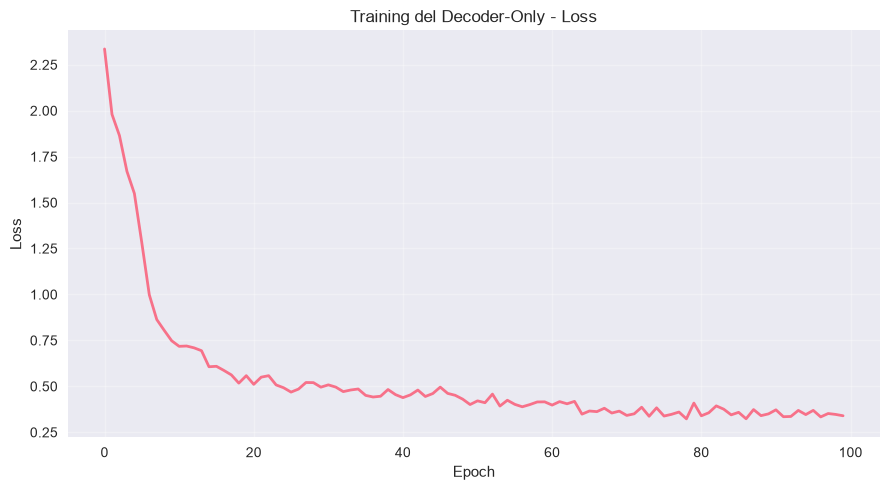

In [21]:
# ============================================================
# CURVA DI LOSS
# ============================================================
# Se il training ha funzionato, la loss deve scendere in modo
# più o meno monotono lungo le epoche: significa che il modello
# sta effettivamente imparando a prevedere il token successivo
# meglio di come faceva con i pesi casuali iniziali.
# ============================================================

plt.figure(figsize=(9, 5))
# history.history["loss"] è una lista con un valore per epoca,
# popolata automaticamente da Keras durante il fit() precedente.
plt.plot(history.history["loss"], linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training del Decoder-Only - Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Curva di Accuracy

🔍 **Cosa viene fatto realmente:** stesso principio della loss, sulla frazione di predizioni corrette.

🛠️ **Strumenti usati:** `history.history["accuracy"]`; `matplotlib.pyplot.plot`.

🎯 **Obiettivo:** con un corpus piccolo e ripetitivo, aspettarsi un'accuracy vicina a 1.0.


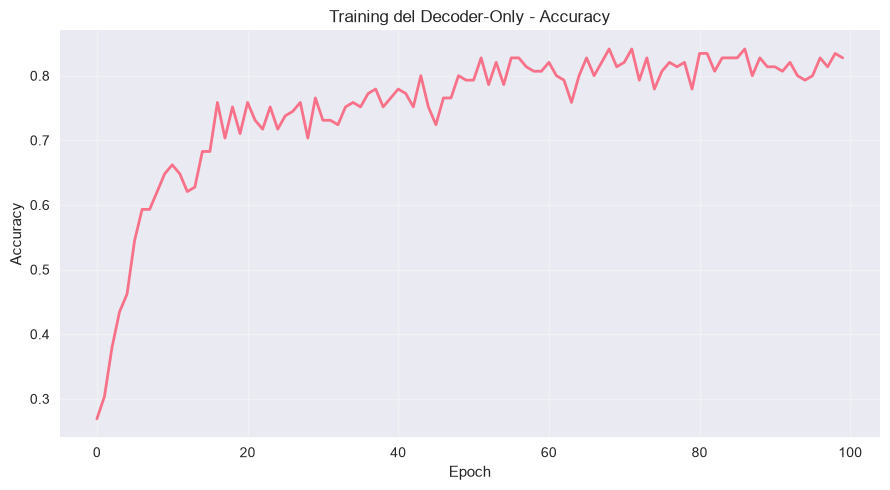

In [22]:
# ============================================================
# CURVA DI ACCURACY
# ============================================================
# Accuracy = frazione di posizioni in cui il token più probabile
# previsto dal modello coincide esattamente col token target.
# Con un corpus così piccolo e ripetitivo ci aspettiamo che salga
# vicino a 1.0: il modello può "memorizzare" facilmente pattern
# come "il gatto ..." -> "dorme"/"mangia"/"corre".
# ============================================================

plt.figure(figsize=(9, 5))
# Stessa fonte della cella precedente (l'oggetto history restituito
# da fit()), ma leggiamo la voce "accuracy" invece di "loss".
plt.plot(history.history["accuracy"], linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training del Decoder-Only - Accuracy")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Blocco 5 — Visualizzazione DOPO il training

🔗 **Legame col blocco precedente:** ripetiamo la visualizzazione del Blocco 3, ma su `mini_gpt_train`, appena addestrato.

🔍 **Cosa viene fatto realmente:** stessa self-attention causale di prima; la maschera resta identica (proprietà strutturale), ma i valori nella parte triangolare inferiore ora riflettono ciò che il modello ha imparato.

🛠️ **Strumenti usati:** stessi strumenti del Blocco 3 (`mini_gpt_train.embedding`, `mini_gpt_train.pos_encoding`, `block.mha(..., return_attention_scores=True, use_causal_mask=True)`, `matplotlib.pyplot.imshow`), applicati questa volta al modello addestrato.

🎯 **Obiettivo:** confrontare "prima" e "dopo" per vedere l'effetto tangibile del training sui pesi di attenzione.


SELF-ATTENTION CAUSALE DOPO IL TRAINING

Matrice di Self-Attention causale - Head 1 (dopo il training):

[[1.    0.    0.    0.   ]
 [0.391 0.609 0.    0.   ]
 [0.169 0.258 0.573 0.   ]
 [0.099 0.145 0.319 0.437]]


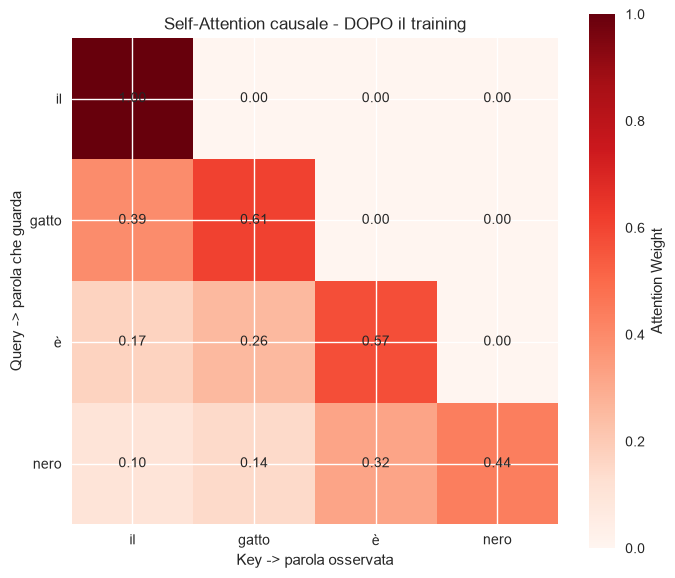


Come prima, la parte triangolare superiore resta a zero (maschera
causale). La differenza rispetto a PRIMA del training è nei valori
della parte triangolare inferiore: ora riflettono ciò che il
modello ha imparato sulle relazioni tra queste parole nel corpus.


In [23]:
# ============================================================
# SELF-ATTENTION CAUSALE DOPO IL TRAINING
# ============================================================
# Ripetiamo esattamente la stessa visualizzazione fatta PRIMA del
# training (sul modello non addestrato), ma ora su mini_gpt_train,
# che ha appena finito 100 epoche di fit(). Il confronto tra le
# due matrici mostra concretamente l'effetto del training: i pesi
# non sono più determinati solo dalla maschera causale, ma anche
# da ciò che il modello ha imparato dal corpus.
# ============================================================

print("SELF-ATTENTION CAUSALE DOPO IL TRAINING\n")

frase_attention = ["il", "gatto", "è", "nero"]
input_attention = tf.constant([[word_to_id[word] for word in frase_attention]])

x_attention = mini_gpt_train.embedding(input_attention)
x_attention = mini_gpt_train.pos_encoding(x_attention)

block_attention = mini_gpt_train.decoder_blocks[0]

attention_output, attention_scores = block_attention.mha(
    x_attention, x_attention, x_attention,
    return_attention_scores=True,
    training=False,
    use_causal_mask=True,
)

attention_matrix = attention_scores[0, 0].numpy()

print("Matrice di Self-Attention causale - Head 1 (dopo il training):\n")
print(np.round(attention_matrix, 3))

plt.figure(figsize=(7, 6))
plt.imshow(attention_matrix, cmap="Reds")
plt.colorbar(label="Attention Weight")
plt.xticks(range(len(frase_attention)), frase_attention)
plt.yticks(range(len(frase_attention)), frase_attention)
plt.xlabel("Key -> parola osservata")
plt.ylabel("Query -> parola che guarda")
plt.title("Self-Attention causale - DOPO il training")

for i in range(len(frase_attention)):
    for j in range(len(frase_attention)):
        plt.text(j, i, f"{attention_matrix[i, j]:.2f}", ha="center", va="center")

plt.tight_layout()
plt.show()

print("\nCome prima, la parte triangolare superiore resta a zero (maschera")
print("causale). La differenza rispetto a PRIMA del training è nei valori")
print("della parte triangolare inferiore: ora riflettono ciò che il")
print("modello ha imparato sulle relazioni tra queste parole nel corpus.")


## Blocco 6 — Generazione autoregressiva

🔗 **Legame col blocco precedente:** abbiamo un modello addestrato con pesi aggiornati. Ora lo usiamo per generare testo, un token alla volta.

🔍 **Cosa viene fatto realmente:** partiamo da una frase seed, chiediamo al modello il prossimo token più probabile (`argmax`, greedy decoding) e lo aggiungiamo alla frase, ripetendo. **Eseguito realmente sul modello appena addestrato**, non è una simulazione.

🛠️ **Strumenti usati:** chiamata diretta al modello `modello(input_ids, training=False)` per ottenere i logit; `tf.argmax(...)` per il greedy decoding; un ciclo `for` Python che ripete il procedimento token per token.

🎯 **Obiettivo:** vedere concretamente cosa significa "un decoder-only addestrato", oltre a un numero di loss che scende.


In [24]:
# ============================================================
# GENERAZIONE AUTOREGRESSIVA COL MODELLO ADDESTRATO
# ============================================================
# La loss che scende e l'accuracy che sale sono numeri: qui
# vediamo l'effetto concreto del training, usando mini_gpt_train
# per generare testo parola per parola, esattamente come fa GPT
# (ma su un vocabolario di 9 parole invece che ~50000).
#
# Procedimento (greedy decoding, il più semplice possibile):
#   1) partiamo da una frase seed
#   2) chiediamo al modello la distribuzione sul token successivo
#   3) prendiamo il token più probabile (argmax)
#   4) lo aggiungiamo alla frase e ripetiamo
#
# Questo è IL motivo per cui abbiamo addestrato un decoder-only:
# un modello non addestrato (pesi casuali) genererebbe parole a
# caso, senza alcuna coerenza con il seed.
# ============================================================

print("GENERAZIONE AUTOREGRESSIVA (greedy)\n")


def genera_testo(modello, seed_words, n_token_da_generare=5, seq_len=seq_len_train):
    """Genera token successivi a partire da seed_words, uno alla volta.

    Ad ogni passo ricostruiamo una finestra di lunghezza seq_len
    (padding con l'ultimo id noto se la frase è più corta), perché
    il modello è stato addestrato con sequenze di quella lunghezza.
    """
    token_ids = [word_to_id[w] for w in seed_words]

    for _ in range(n_token_da_generare):
        # Prendiamo solo gli ultimi seq_len token come contesto
        contesto = token_ids[-seq_len:]

        # Se il contesto è più corto di seq_len, lo allunghiamo
        # ripetendo il primo token (padding semplice, solo per demo)
        while len(contesto) < seq_len:
            contesto = [contesto[0]] + contesto

        input_ids = tf.constant([contesto])
        logits = modello(input_ids, training=False)  # shape: (1, seq_len, vocab_size)

        # Ci interessa solo la predizione per l'ULTIMA posizione:
        # è la previsione del token che segue tutto il contesto.
        prossimo_logit = logits[0, -1, :]
        prossimo_id = int(tf.argmax(prossimo_logit).numpy())

        token_ids.append(prossimo_id)

    return [id_to_word[i] for i in token_ids]


seed = ["il", "gatto"]
generato = genera_testo(mini_gpt_train, seed, n_token_da_generare=5)

print(f"Seed: {' '.join(seed)}")
print(f"Generato: {' '.join(generato)}")

# Proviamo anche un secondo seed per vedere se il pattern si ripete
seed2 = ["il", "cane"]
generato2 = genera_testo(mini_gpt_train, seed2, n_token_da_generare=5)

print(f"\nSeed: {' '.join(seed2)}")
print(f"Generato: {' '.join(generato2)}")

print("\nNOTA:")
print("Il corpus di training conteneva SOLO frasi come 'il gatto dorme',")
print("'il cane è nero', ecc. Il modello ha imparato queste associazioni")
print("specifiche: non generalizza a frasi nuove come farebbe un vero LLM")
print("addestrato su miliardi di parole. È comunque la stessa identica")
print("meccanica (autoregressiva, decoder-only, causal mask) usata da GPT.")


GENERAZIONE AUTOREGRESSIVA (greedy)

Seed: il gatto
Generato: il gatto è felice il cane è

Seed: il cane
Generato: il cane dorme il cane mangia il

NOTA:
Il corpus di training conteneva SOLO frasi come 'il gatto dorme',
'il cane è nero', ecc. Il modello ha imparato queste associazioni
specifiche: non generalizza a frasi nuove come farebbe un vero LLM
addestrato su miliardi di parole. È comunque la stessa identica
meccanica (autoregressiva, decoder-only, causal mask) usata da GPT.
